# Evaluating PyTorch and Keras models

`aggmetrics` takes NumPy arrays, so it works with any framework once the predictions are on the CPU as
arrays. There is nothing to install besides the package and nothing framework-specific in it. What the
frameworks add are habits worth looking at: predictions that come as logits, evaluation done batch by batch,
and metrics logged at the end of each epoch. This notebook trains the same small network in PyTorch and in
Keras on the multilabel *yeast* data and shows the points where the measure can go wrong.

It covers four things: moving the outputs of a model to the package, the multiclass case, the difference
between pooling the batches and averaging a measure over them, and a Keras callback that logs a measure
every epoch. It does not compare the two frameworks, and the two networks, trained differently, are not
comparable to each other.

In [1]:
# Installs only what is missing (for example in Colab, which already has torch and keras).
import importlib.util
missing = [p for p, m in [("aggmetrics", "aggmetrics"), ("torch", "torch"), ("keras", "keras"),
                          ("matplotlib", "matplotlib")] if importlib.util.find_spec(m) is None]
if missing:
    %pip install -q {" ".join(missing)}

In [2]:
import io
import os
import urllib.request
import warnings
warnings.filterwarnings("ignore")
os.environ["KERAS_BACKEND"] = "torch"            # must be set before keras is imported
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras

from aggmetrics import IndicatorMatrix, fold_aggregate, get_measure

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## The data

*yeast* has 2417 genes, 103 features and 14 labels, each gene having several labels. The split is random,
1800 genes for training and 617 for testing, and the features are standardised with the training statistics.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/yeast.npz"
local = Path("../data/yeast.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    X, Y = z["X"].astype("float32"), z["Y"].astype("float32")

rng = np.random.default_rng(0)
order = rng.permutation(len(X))
train, test = order[:1800], order[1800:]
mean, std = X[train].mean(axis=0), X[train].std(axis=0)
Xs = (X - mean) / std
print("train, test, features, labels:", len(train), len(test), X.shape[1], Y.shape[1])

train, test, features, labels: 1800 617 103 14


## PyTorch

A two-layer network trained with binary cross-entropy on the logits. The evaluation has three rules: put the
model in `eval` mode, switch gradients off, and move the result to NumPy on the CPU.

In [4]:
torch.manual_seed(0)
net = torch.nn.Sequential(torch.nn.Linear(103, 64), torch.nn.ReLU(), torch.nn.Linear(64, 14))
optimiser = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()
x_train, y_train = torch.tensor(Xs[train]), torch.tensor(Y[train])

for epoch in range(60):
    net.train()
    perm = torch.randperm(len(x_train))
    for i in range(0, len(x_train), 64):
        batch = perm[i:i + 64]
        optimiser.zero_grad()
        loss_fn(net(x_train[batch]), y_train[batch]).backward()
        optimiser.step()

net.eval()
with torch.no_grad():                              # no gradients while evaluating
    logits = net(torch.tensor(Xs[test])).numpy()   # to NumPy, on the CPU
y_test = Y[test].astype(int)
print("logits:", logits.shape, logits.dtype)

logits: (617, 14) float32


In [5]:
probs = 1 / (1 + np.exp(-logits))               # sigmoid
im_probs = IndicatorMatrix(y_test, probs, task="multilabel")                  # threshold 0.5 on probabilities
im_logits = IndicatorMatrix(y_test, logits, task="multilabel", threshold=0.0)  # the same decision on the logits
print("same decisions:", bool((im_probs.P == im_logits.P).all()))

rows = {}
for ms in ("f1", "jaccard", "mcc"):
    rows[ms] = {op: im_probs.compute(ms, op) for op in ("micro", "macro", "weighted", "exemplar")}
pd.DataFrame(rows).T.round(4)

same decisions: True


,micro,macro,weighted,exemplar
f1,0.6310,0.4187,0.6008,0.6024
jaccard,0.4609,0.3038,0.4576,0.5019
mcc,0.4873,0.2305,0.2383,0.4951


The network outputs logits, which can be turned into decisions in two equivalent ways: apply the sigmoid and
threshold at 0.5, or threshold the logits at 0. The two give the same decisions, so no sigmoid is needed
before the package. The table gives three measures under four operators for the test set: micro and macro
differ by 0.21 for F1 and 0.26 for MCC, which is the same sensitivity to the operator seen in notebook 03.

For a single-label problem the output of the network is a matrix of scores, one column per class, and the
package accepts it as it is. The check below uses random scores, so it shows only that a score matrix and
its argmax labels are the same prediction, not how well anything works.

In [6]:
g = torch.Generator().manual_seed(1)
scores = torch.randn(200, 5, generator=g)                       # random scores: only the equivalence is shown
labels = torch.randint(0, 5, (200,), generator=g).numpy()
a = IndicatorMatrix(labels, scores.numpy(), task="multiclass")                 # a score matrix
b = IndicatorMatrix(labels, scores.argmax(dim=1).numpy(), task="multiclass")   # the argmax labels
print("same predictions:", bool((a.P == b.P).all()), "| macro-F1:", round(a.compute("f1", "macro"), 4))

same predictions: True | macro-F1: 0.1678


## Batches: pool them, do not average them

A loop that evaluates a held-out set in batches often computes the measure on every batch and averages. For
a measure that is not a mean of per-example values, that is not the value on the whole set. The package has
the pooled alternative: `fold_aggregate` with `pooling="pooled"` adds the cell counts of the batches
(the operator for folds in notebook 05) and then computes the measure. The table compares the two with
batches of 32, and 617 is not a multiple of it, so the last batch has 9 examples.

In [7]:
def batch_ims(size):
    return [IndicatorMatrix(y_test[i:i + size], probs[i:i + size], task="multilabel")
            for i in range(0, len(y_test), size)]

ims32 = batch_ims(32)
print("batches:", len(ims32), "| size of the last:", ims32[-1].n)
rows = {}
for ms, op in (("f1", "micro"), ("f1", "macro"), ("mcc", "macro")):
    rows[f"{op} {ms}"] = {
        "whole test set": im_probs.compute(ms, op),
        "pooled over batches": fold_aggregate(ims32, ms, op, pooling="pooled"),
        "mean of batch values": fold_aggregate(ims32, ms, op, pooling="averaged"),
    }
pd.DataFrame(rows).T.round(4)

batches: 20 | size of the last: 9


,whole test set,pooled over batches,mean of batch values
micro f1,0.6310,0.6310,0.6302
macro f1,0.4187,0.4187,0.4261
macro mcc,0.2305,0.2305,0.2562


In [8]:
sizes = [8, 16, 32, 64, 128, len(y_test)]
whole = {ms: im_probs.compute(ms, "macro") for ms in ("f1", "mcc")}
gap = {ms: [fold_aggregate(batch_ims(s), ms, "macro", pooling="averaged") - whole[ms] for s in sizes]
       for ms in ("f1", "mcc")}
table = pd.DataFrame(gap, index=sizes).rename_axis("batch size")
table["batches with undefined macro-MCC"] = [
    sum(np.isnan(im.compute("mcc", "macro")) for im in batch_ims(s)) for s in sizes]
table.round(4)

,f1,mcc,batches with undefined macro-MCC
batch size,,,
8,0.0280,NaN,1
16,0.0206,0.0540,0
32,0.0074,0.0257,0
64,0.0063,0.0207,0
128,0.0014,0.0109,0
617,0.0000,0.0000,0


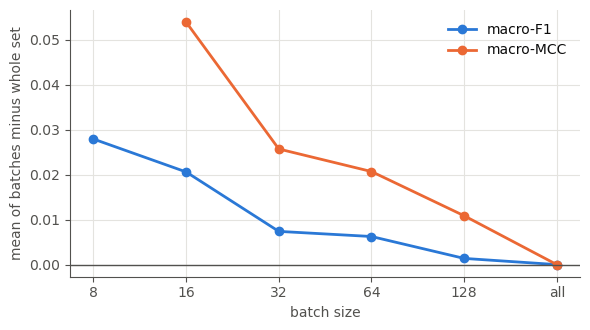

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(len(sizes)), gap["f1"], marker="o", color=BLUE, label="macro-F1")
ax.plot(range(len(sizes)), gap["mcc"], marker="o", color=ORANGE, label="macro-MCC")
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(range(len(sizes))); ax.set_xticklabels(["8", "16", "32", "64", "128", "all"])
ax.set_xlabel("batch size"); ax.set_ylabel("mean of batches minus whole set")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Pooling the batches gives exactly the value on the whole set, to four decimals, for all three measures.
Averaging the batch values gives a different number: in this run macro-F1 is 0.0074 higher (0.4261 against
0.4187) and macro-MCC 0.0257 higher (0.2562 against 0.2305, 11% more). The direction was not checked on other
models, and only the size of the gap for this model is reported here. The gap depends on the batch size, as
the next table shows, and it shrinks as the batches grow.

With batches of 8, one of the 78 batches has an undefined macro-MCC (every label of that batch is
undefined), and the average over the batches is `NaN`. Pooled, the counts of that batch are simply added to
the others.

When the test set is too large to keep all the predictions, the counts can be accumulated instead, and the
measure applied once at the end. Below, a loop keeps only a 4 by 14 array of counts, and the macro-F1 from
it is the same as on the whole set.

In [10]:
def label_counts(y, p):
    # per-label tp, fp, fn, tn of one batch
    y, p = y.astype(bool), p.astype(bool)
    return np.array([(y & p).sum(0), (~y & p).sum(0), (y & ~p).sum(0), (~y & ~p).sum(0)])

total = np.zeros((4, 14))
for i in range(0, len(y_test), 32):                # one batch at a time, nothing else is kept
    total += label_counts(y_test[i:i + 32], probs[i:i + 32] > 0.5)

f1 = get_measure("f1")
streamed = np.mean([f1(*total[:, j]) for j in range(14)])
print("macro-F1 from accumulated counts:", round(float(streamed), 6))
print("macro-F1 on the whole test set  :", round(im_probs.compute("f1", "macro"), 6))

macro-F1 from accumulated counts: 0.418724
macro-F1 on the whole test set  : 0.418724


The two values are equal to six decimals. This is the way to log a measure from a long evaluation loop:
accumulate the counts and apply the measure at the end of the epoch.

## Keras

The same network in Keras 3, with the PyTorch backend chosen so that only one framework has to be installed.
The callback below predicts on the held-out set at the end of each epoch and adds the measure to the logs, so
that it appears in `history` and can be used by other callbacks such as early stopping. `model.predict`
returns NumPy whatever the backend, so the callback is the same with TensorFlow or JAX. Because the whole
held-out set is predicted once per epoch, the value is the pooled one by construction.

The test set is used as the held-out set to keep the example short. In a real run it should be a validation
split, so that the test set is used only once.

In [11]:
keras.utils.set_random_seed(0)
model = keras.Sequential([
    keras.layers.Input((103,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(14, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")


class AggMetrics(keras.callbacks.Callback):
    """Adds an aggmetrics measure on held-out data to the logs at the end of each epoch."""

    def __init__(self, x, y, measure, how, **kwargs):
        super().__init__()
        self.x, self.y, self.measure, self.how, self.kwargs = x, y, measure, how, kwargs

    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.x, verbose=0)           # NumPy, whatever the backend
        im = IndicatorMatrix(self.y, p, task="multilabel", **self.kwargs)
        logs[f"val_{self.how}_{self.measure}"] = im.compute(self.measure, self.how)


callbacks = [AggMetrics(Xs[test], y_test, "f1", "macro"), AggMetrics(Xs[test], y_test, "f1", "micro")]
history = model.fit(Xs[train], Y[train], epochs=30, batch_size=64, verbose=0, callbacks=callbacks)
pd.DataFrame(history.history).iloc[[0, 9, 19, 29]].round(4)

,loss,val_macro_f1,val_micro_f1
0,0.7098,0.3133,0.4634
9,0.4116,0.3396,0.6178
19,0.3675,0.3872,0.6303
29,0.3357,0.4007,0.6303


Macro-F1 goes from 0.313 to 0.401 over the 30 epochs and micro-F1 from 0.463 to 0.630, so the two operators
tell different stories about the same training run: micro-F1 rises fast in the first ten epochs (0.463 to
0.618) and by the twentieth is at 0.630, where it stays, while macro-F1 is still rising at the thirtieth
(0.387 at the twentieth, 0.401 at the thirtieth). A single logged measure with an unnamed operator would hide that. The numbers
are not comparable with those of the PyTorch network, which was trained for different numbers of epochs
and had no early stopping.

## Summary

- Any model works once its outputs are NumPy arrays. Logits can be thresholded at 0, and a score matrix can
  be given directly for a single-label problem. Evaluate in `eval` mode without gradients.
- Do not average a measure over batches. Pool the batches with `fold_aggregate(..., pooling="pooled")`, or
  accumulate per-label counts and apply the measure once. For macro-MCC the mean of the batch values was 11%
  above the whole-set value for batches of 32 in this run.
- Small batches can leave a measure undefined in some batches, and an average over the batches then
  becomes `NaN`.
- Log the operator with the measure. In this run the same training curve looks different under micro and
  macro F1.